# 01 – Exploratory Data Analysis: Fake Job Postings

**Dataset:** EMSCAD, from Kaggle's *Real or Fake Job Posting Prediction* (`data/fake_job_postings.csv`). Target: `fraudulent` (1 = fake).

**Questions this notebook answers before any modelling:**
1. How imbalanced are the classes? (This decides which metrics are meaningful.)
2. Where is data missing, and is *missingness itself* a fraud signal?
3. How do fake postings differ on company logo, salary, screening questions, telecommuting, industry, function and text length?
4. What does the raw text look like? (This decides the cleaning steps in Phase 2.)

Each finding below feeds a feature or a decision in `src/preprocess.py` and `src/train.py`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "fake_job_postings.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

# One chart style everywhere: blue = real, orange = fake; thin marks, hairline grid
REAL, FAKE = "#2a78d6", "#eb6834"
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
COLORS = {"Real": REAL, "Fake": FAKE}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30, "display.max_colwidth", 80)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("saved", (FIG_DIR / name).relative_to(ROOT))

In [2]:
assert DATA.exists(), f"Missing dataset: put fake_job_postings.csv in {DATA.parent}"
df = pd.read_csv(DATA)
df["label"] = df["fraudulent"].map({0: "Real", 1: "Fake"})
print(df.shape)
df.head(3)

(17880, 19)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,label
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking s...","Food52, a fast-growing, James Beard Award-winning online food community and ...",Experience with content management systems a major plus (any blogging counts...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0,Real
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worl...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer s...,What we expect from you:Your key responsibility will be to communicate with ...,What you will get from usThrough being part of the 90 Seconds team you will ...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,Real
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies...,"Our client, located in Houston, is actively seeking an experienced Commissio...",Implement pre-commissioning and commissioning procedures for rotary equipmen...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0,Real


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [4]:
# Exact duplicate postings (ignoring the ID): these could leak between train and test later
dupes = df.drop(columns="job_id").duplicated()
print(f"Exact duplicate rows (excluding job_id): {dupes.sum()}")
print(df.loc[dupes, "label"].value_counts())

Exact duplicate rows (excluding job_id): 281
label
Real    271
Fake     10
Name: count, dtype: int64


**Findings:** 281 rows are exact duplicates once `job_id` is ignored (271 real, 10 fake).
If one copy lands in train and the other in test, the model is scored on a posting it has already seen, which inflates the test score.
→ **Phase 2: drop exact duplicates *before* the train/test split.**

## 1. Class balance

In [5]:
counts = df["label"].value_counts().reindex(["Real", "Fake"])
pct = counts / counts.sum() * 100
display(pd.DataFrame({"count": counts, "percent": pct.round(2)}))
print(f"A model that always predicts 'Real' scores {pct['Real']:.2f}% accuracy and catches 0 fakes.")

,count,percent
label,,
Real,17014,95.16
Fake,866,4.84


A model that always predicts 'Real' scores 95.16% accuracy and catches 0 fakes.


saved reports/figures/01_class_balance.png


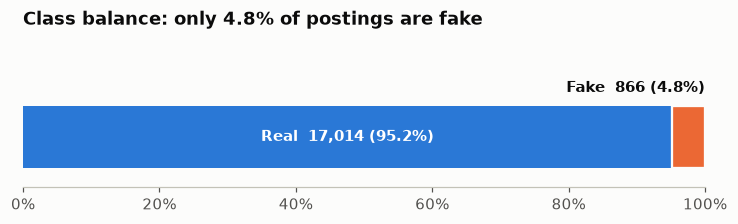

In [6]:
fig, ax = plt.subplots(figsize=(8, 1.7))
ax.barh(0, pct["Real"], color=REAL, height=0.5)
ax.barh(0, pct["Fake"], left=pct["Real"], color=FAKE, height=0.5, edgecolor=SURFACE, linewidth=1.5)
ax.text(pct["Real"] / 2, 0, f"Real  {counts['Real']:,} ({pct['Real']:.1f}%)", ha="center", va="center", color="white", weight="bold")
ax.text(100, 0.33, f"Fake  {counts['Fake']:,} ({pct['Fake']:.1f}%)", ha="right", va="bottom", color=INK, weight="bold")
ax.set(xlim=(0, 100), ylim=(-0.4, 0.75), yticks=[])
ax.xaxis.set_major_formatter(PercentFormatter())
ax.spines["left"].set_visible(False); ax.grid(False)
ax.set_title(f"Class balance: only {pct['Fake']:.1f}% of postings are fake")
save(fig, "01_class_balance.png"); plt.show()

**Findings:**
- **17,014 real (95.16%)** vs **866 fake (4.84%)**: roughly 1 fake in 20.
- A model that always says "Real" gets **95.16% accuracy** and catches **zero** fakes, so accuracy is useless here.
  → Judge models on **precision, recall, F1 and PR-AUC for the fake class**.
- → Use a **stratified** split so train and test both keep the 4.84% fake rate, and handle the imbalance in training (class weights vs SMOTE, compared in Phase 3).

## 2. Missing values: is *missing* itself a signal?

In [7]:
real, fake = df[df.fraudulent == 0], df[df.fraudulent == 1]
missing = pd.DataFrame({
    "overall_%": df.isna().mean() * 100,
    "real_%": real.isna().mean() * 100,
    "fake_%": fake.isna().mean() * 100,
}).query("`overall_%` > 0").round(1)
missing["gap_fake_minus_real"] = missing["fake_%"] - missing["real_%"]
missing.sort_values("gap_fake_minus_real", ascending=False)

,overall_%,real_%,fake_%,gap_fake_minus_real
company_profile,18.5,16.0,67.8,51.8
required_experience,39.4,38.9,50.2,11.3
employment_type,19.4,19.0,27.8,8.8
required_education,45.3,45.0,52.1,7.1
industry,27.4,27.2,31.8,4.6
requirements,15.1,14.9,17.8,2.9
function,36.1,36.0,38.9,2.9
benefits,40.3,40.2,42.0,1.8
location,1.9,1.9,2.2,0.3
description,0.0,0.0,0.1,0.1


In [8]:
# Number of missing fields per posting, by class (becomes a feature in Phase 2)
n_missing = df.drop(columns=["label"]).isna().sum(axis=1)
n_missing.groupby(df["label"]).describe()[["mean", "50%", "max"]].round(2)

,mean,50%,max
label,,,
Fake,4.66,5.0,11.0
Real,3.88,3.0,11.0


saved reports/figures/02_missing_by_class.png


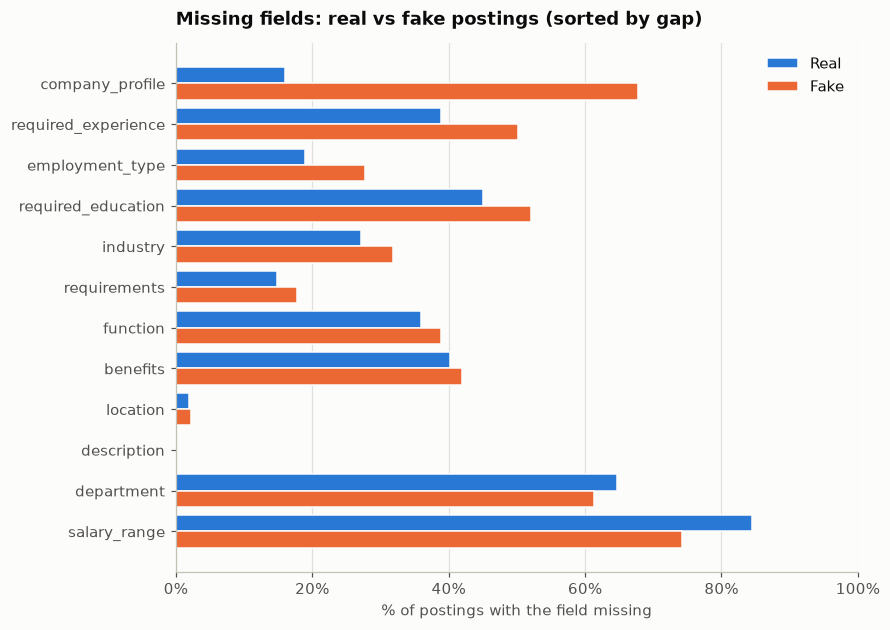

In [9]:
m = missing.sort_values("gap_fake_minus_real")          # biggest gap ends up at the top
y, h = np.arange(len(m)), 0.4
fig, ax = plt.subplots(figsize=(8, 0.42 * len(m) + 1.2))
ax.barh(y + h / 2, m["real_%"], height=h, color=REAL, label="Real", edgecolor=SURFACE, linewidth=1)
ax.barh(y - h / 2, m["fake_%"], height=h, color=FAKE, label="Fake", edgecolor=SURFACE, linewidth=1)
ax.set(yticks=y, yticklabels=m.index, xlim=(0, 100), xlabel="% of postings with the field missing")
ax.xaxis.set_major_formatter(PercentFormatter()); ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
ax.set_title("Missing fields: real vs fake postings (sorted by gap)")
save(fig, "02_missing_by_class.png"); plt.show()

**Findings:**
- `company_profile` is the standout: missing in **67.8% of fakes vs 16.0% of real** postings (a 51.8-point gap). A fake company often has nothing to describe.
- Fakes also skip `required_experience` (50.2% vs 38.9%), `employment_type` (27.8% vs 19.0%) and `required_education` (52.1% vs 45.0%) more often.
- It goes the other way for `salary_range`: fakes are *more* likely to list a salary (missing in 74.2% of fakes vs 84.5% of real).
- A fake posting has **4.66 missing fields on average (median 5)** vs **3.88 (median 3)** for a real one.
- → **Missing values are a signal, so don't impute them away.** Phase 2: missing categoricals become a `"Missing"` category, missing text becomes `""`, and an `n_missing` count feature is added.

## 3. Binary signals: company logo, salary, screening questions, telecommuting
`salary_range` is mostly empty, so I turn it into a flag: *was a salary listed at all?*

In [10]:
df["has_salary"] = df["salary_range"].notna().astype(int)
FLAGS = {"has_company_logo": "Has company logo", "has_salary": "Lists a salary range",
         "has_questions": "Has screening questions", "telecommuting": "Telecommuting (remote)"}

flag_tbl = pd.DataFrame({
    "real_%_with_flag": df[df.fraudulent == 0][list(FLAGS)].mean() * 100,
    "fake_%_with_flag": df[df.fraudulent == 1][list(FLAGS)].mean() * 100,
    "fraud_rate_%_if_1": [df.loc[df[c] == 1, "fraudulent"].mean() * 100 for c in FLAGS],
    "fraud_rate_%_if_0": [df.loc[df[c] == 0, "fraudulent"].mean() * 100 for c in FLAGS],
}).round(1).rename(index=FLAGS)
flag_tbl

,real_%_with_flag,fake_%_with_flag,fraud_rate_%_if_1,fraud_rate_%_if_0
Has company logo,81.9,32.7,2.0,15.9
Lists a salary range,15.5,25.8,7.8,4.3
Has screening questions,50.2,28.9,2.8,6.8
Telecommuting (remote),4.1,7.4,8.3,4.7


saved reports/figures/03_binary_signals.png


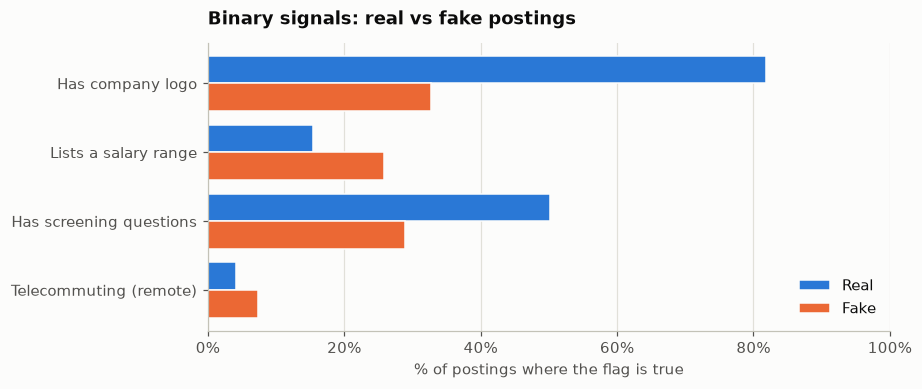

In [11]:
f = flag_tbl.iloc[::-1]
y, h = np.arange(len(f)), 0.4
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(y + h / 2, f["real_%_with_flag"], height=h, color=REAL, label="Real", edgecolor=SURFACE, linewidth=1)
ax.barh(y - h / 2, f["fake_%_with_flag"], height=h, color=FAKE, label="Fake", edgecolor=SURFACE, linewidth=1)
ax.set(yticks=y, yticklabels=f.index, xlim=(0, 100), xlabel="% of postings where the flag is true")
ax.xaxis.set_major_formatter(PercentFormatter()); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Binary signals: real vs fake postings")
save(fig, "03_binary_signals.png"); plt.show()

**Findings:**
- **Company logo** is the strongest flag: 81.9% of real postings have one vs only 32.7% of fakes.
  Postings *without* a logo are fake **15.9%** of the time vs **2.0%** with a logo (about 8× higher).
- **Screening questions:** 50.2% of real vs 28.9% of fake postings have them (fraud rate 6.8% without vs 2.8% with). Real employers invest more in the hiring process.
- **Salary listed:** fakes list a salary *more* often (25.8% vs 15.5%), with a fraud rate of 7.8% when listed vs 4.3% when not. A plausible reason is that the pay is bait (a hypothesis, not tested here).
- **Telecommuting:** 7.4% of fakes vs 4.1% of real postings are remote (fraud rate 8.3% vs 4.7%). The difference is real, but few postings are remote.
- None of these is a rule: a third of fakes *do* have a logo. That's why we need a model that combines many weak signals.
- → `has_company_logo`, `has_questions` and `telecommuting` go in as they are, plus a new `has_salary` flag.

## 4. Industry and job function
Fraud rate per category. Categories with fewer than `MIN_N` postings are dropped, since a rate from a handful of rows is noise.
Missing values are kept as their own category, `"Missing"`.

In [12]:
MIN_N = 50
overall = df["fraudulent"].mean() * 100

def fraud_rate_by(col, min_n=MIN_N):
    g = df[col].fillna("Missing").to_frame().assign(fraudulent=df["fraudulent"])
    g = g.groupby(col)["fraudulent"].agg(n="size", fraud_rate_pct="mean")
    g["fraud_rate_pct"] = (g["fraud_rate_pct"] * 100).round(1)
    return g[g["n"] >= min_n].sort_values("fraud_rate_pct", ascending=False)

print(f"Overall fraud rate: {overall:.2f}%")
print(f"industry: {df['industry'].nunique()} categories | function: {df['function'].nunique()} categories")
display(fraud_rate_by("industry").head(10))
display(fraud_rate_by("function").head(10))

Overall fraud rate: 4.84%
industry: 131 categories | function: 37 categories


,n,fraud_rate_pct
industry,,
Oil & Energy,287,38.0
Accounting,159,35.8
"Leisure, Travel & Tourism",76,27.6
Hospitality,88,15.9
Real Estate,175,13.7
"Health, Wellness and Fitness",127,11.8
Hospital & Health Care,497,10.3
Telecommunications,342,7.6
Entertainment,74,6.8


,n,fraud_rate_pct
function,,
Administrative,630,18.9
Accounting/Auditing,212,13.7
Other,325,9.8
Finance,172,8.7
Engineering,1348,8.4
Business Development,228,5.7
Advertising,90,5.6
Project Management,183,5.5
Customer Service,1229,5.5


saved reports/figures/04_industry_function.png


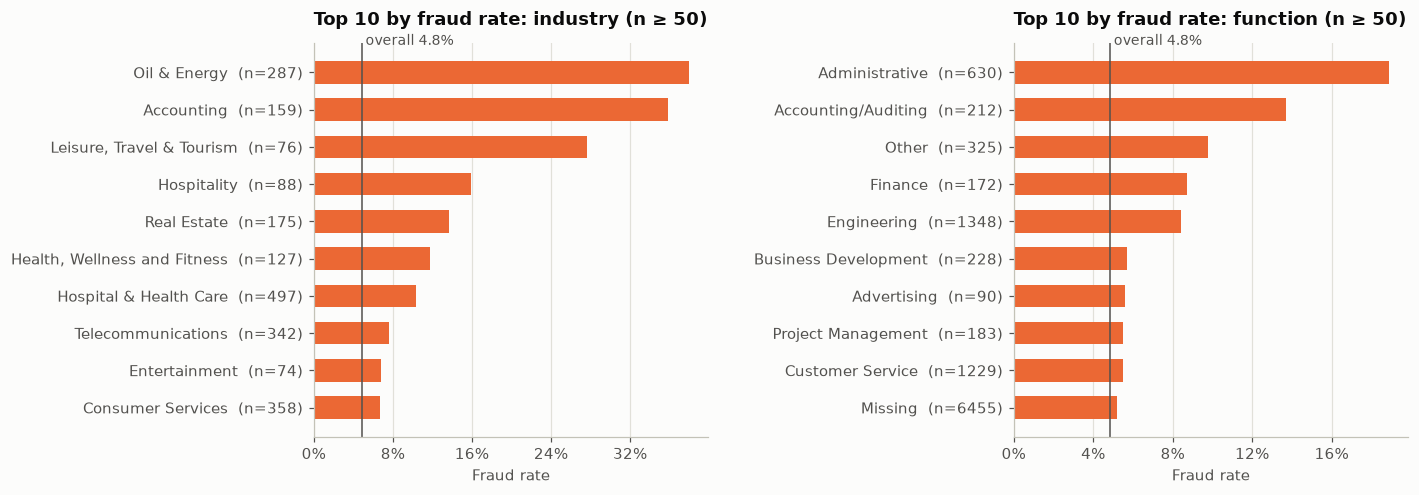

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, col in zip(axes, ["industry", "function"]):
    top = fraud_rate_by(col).head(10).iloc[::-1]
    ax.barh([f"{i}  (n={n})" for i, n in zip(top.index, top["n"])], top["fraud_rate_pct"], color=FAKE, height=0.6)
    ax.axvline(overall, color=MUTED, linewidth=1)
    ax.text(overall, len(top) - 0.35, f" overall {overall:.1f}%", color=MUTED, va="bottom", fontsize=9)
    ax.xaxis.set_major_locator(MaxNLocator(5)); ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set(xlabel="Fraud rate", title=f"Top 10 by fraud rate: {col} (n ≥ {MIN_N})")
fig.tight_layout(w_pad=3)
save(fig, "04_industry_function.png"); plt.show()

**Findings:**
- Against a 4.84% base rate, some industries stand far above it: **Oil & Energy 38.0%** (n=287), **Accounting 35.8%** (n=159), **Leisure, Travel & Tourism 27.6%** (n=76).
- By function: **Administrative 18.9%** (n=630) and **Accounting/Auditing 13.7%** (n=212).
- There are 131 industries and 37 functions, many of them tiny.
- But is the Oil & Energy spike really "oil jobs are risky"? The next cell checks.

In [14]:
# Is the Oil & Energy spike many different scammers, or a few campaigns reposting the same ad?
fake = df[df.fraudulent == 1]
oe = fake[fake["industry"] == "Oil & Energy"]
print(f"All fakes: {len(fake)} | unique descriptions: {fake['description'].nunique()}")
print(f"Oil & Energy fakes: {len(oe)} | unique descriptions: {oe['description'].nunique()} | "
      f"distinct company profiles (blank counted once): {oe['company_profile'].nunique(dropna=False)}")
oe["location"].value_counts().head(5)

All fakes: 866 | unique descriptions: 631
Oil & Energy fakes: 109 | unique descriptions: 93 | distinct company profiles (blank counted once): 9


location
US, TX, Houston                       72
US, CA, Bakersfield                   23
US, CA, Bakersfield, CA                4
US, , Stocton, CA                      2
US, CA, Bakersfield, CA / Mt. Poso     2
Name: count, dtype: int64

**Findings:**
- The 109 Oil & Energy fakes have only **9 distinct company profiles** (counting blank as one), and **72 are in Houston, TX**. The 38% rate comes from a **few scam campaigns reposting similar ads**, not the industry as a whole.
- Across all fakes, only **631 of 866 descriptions are unique**, so reuse is common.
- → **Leakage risk:** with a random split, near-copies of one campaign end up in both train and test, and the model gets credit for *recognising a campaign* rather than *detecting fraud*. Test scores may therefore be **optimistic for brand-new scams**. I'll drop exact duplicates and list this in the README limitations; a stricter test would be a group-aware split, e.g. grouping by company profile.
- → **Recommendation for Phase 2:** add `industry` and `function` as one-hot features (they weren't in the original list), merging rare categories into one "infrequent" bucket. Leave out `location`: it would mostly memorise campaign cities like Houston.

### Other categorical fields (Phase 2 one-hot features)

In [15]:
for col in ["employment_type", "required_experience", "required_education"]:
    print(f"\n{col}")
    display(fraud_rate_by(col, min_n=1))


employment_type


,n,fraud_rate_pct
employment_type,,
Part-time,797,9.3
Missing,3471,6.9
Other,227,6.6
Full-time,11620,4.2
Contract,1524,2.9
Temporary,241,0.8



required_experience


,n,fraud_rate_pct
required_experience,,
Executive,141,7.1
Entry level,2697,6.6
Missing,7050,6.2
Not Applicable,1116,5.4
Director,389,4.4
Mid-Senior level,3809,3.0
Internship,381,2.6
Associate,2297,1.8



required_education


,n,fraud_rate_pct
required_education,,
Some High School Coursework,27,74.1
Certification,170,11.2
High School or equivalent,2080,8.2
Master's Degree,416,7.5
Missing,8105,5.6
Professional,74,5.4
Unspecified,1397,4.4
Doctorate,26,3.8
Some College Coursework Completed,102,2.9


**Findings:**
- `employment_type`: **Part-time 9.3%** fraud (n=797) vs Full-time 4.2%, Contract 2.9%, Temporary 0.8%; Missing 6.9%.
- `required_experience`: **Entry level 6.6%** (n=2,697) and Executive 7.1% (n=141) vs Associate 1.8%, Mid-Senior 3.0%.
- `required_education`: **High School or equivalent 8.2%** (n=2,080) and Certification 11.2% (n=170) vs **Bachelor's 1.9%** (n=5,145).
  "Some High School Coursework" shows 74.1%, but with n=27 it's too small to trust.
- Pattern: **low-barrier jobs** (part-time, entry level, high school) are faked more often, which fits scams aimed at people looking for easy work.
- → One-hot encode all three, with `"Missing"` as its own category and very rare categories merged.

## 5. Text length

In [16]:
TEXT_COLS = ["title", "company_profile", "description", "requirements", "benefits"]
for c in TEXT_COLS:
    df[f"{c}_words"] = df[c].fillna("").str.split().str.len()
len_tbl = df.groupby("label")[[f"{c}_words" for c in TEXT_COLS]].median().T
len_tbl.columns.name = "median words"
len_tbl[["Real", "Fake"]]

median words,Real,Fake
title_words,3.0,3.0
company_profile_words,86.0,0.0
description_words,147.0,113.5
requirements_words,63.0,34.0
benefits_words,6.0,5.0


saved reports/figures/05_text_length.png


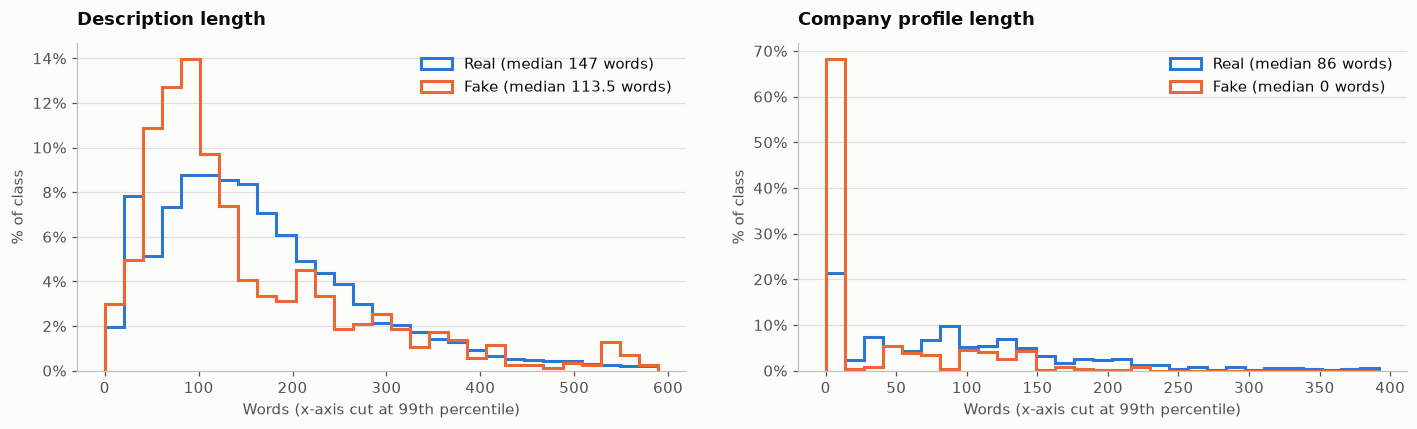

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, name in zip(axes, ["description_words", "company_profile_words"], ["Description", "Company profile"]):
    cap = df[col].quantile(0.99)                          # cut the long tail so the shape is visible
    bins = np.linspace(0, cap, 30)
    for lab in ["Real", "Fake"]:
        s = df.loc[df.label == lab, col]
        kept = s[s <= cap]
        ax.hist(kept, bins=bins, weights=np.full(len(kept), 100 / len(s)), histtype="step",
                linewidth=2, color=COLORS[lab], label=f"{lab} (median {s.median():g} words)")
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.grid(axis="x", visible=False)
    ax.set(xlabel="Words (x-axis cut at 99th percentile)", ylabel="% of class", title=f"{name} length")
    ax.legend()
fig.tight_layout(w_pad=3)
save(fig, "05_text_length.png"); plt.show()

**Findings:**
- Median words, real vs fake: **company_profile 86 vs 0**, **description 147 vs 113.5**, **requirements 63 vs 34**. Title (3 vs 3) and benefits (6 vs 5) barely differ.
- **Fake postings are shorter and less detailed.** The tall orange bar at 0 in the company-profile chart is the same missing-profile signal from section 2.
- → Word counts for `company_profile`, `description` and `requirements` become numeric features. They are right-skewed with long tails, so they get log-transformed and scaled for Logistic Regression (tree models don't need this).

## 6. What does the raw text look like?
This decides the Phase 2 cleaning steps and the email/phone/money features.

In [18]:
text_all = df[TEXT_COLS].fillna("").agg(" ".join, axis=1)

# EMSCAD anonymises contact details as placeholder tokens like #URL_<hash>#; discover which kinds exist
print("Placeholder token types:")
print(text_all.str.extractall(r"#([A-Z]+)_[0-9A-Za-z]+#")[0].value_counts(), "\n")

checks = {
    "html_tag": r"<[a-zA-Z/][^>]*>",
    "html_entity": r"&(?:amp|nbsp|lt|gt|quot);",
    "url_token": r"#URL_",
    "email_token": r"#EMAIL_",
    "phone_token": r"#PHONE_",
    "money_words": r"\$\s?\d|\bearn\b|\bincome\b|\bcash\b|\bmoney\b|\bper (?:hour|day|week)\b",
}
pd.DataFrame({k: text_all.str.contains(p, case=False, regex=True).groupby(df["label"]).mean() * 100
              for k, p in checks.items()}).T[["Real", "Fake"]].round(1).rename_axis("% of postings containing")

Placeholder token types:
0
URL      10849
EMAIL     1461
PHONE      638
Name: count, dtype: int64 



label,Real,Fake
% of postings containing,,
html_tag,0.0,0.0
html_entity,42.6,43.6
url_token,31.5,30.8
email_token,6.8,20.1
phone_token,2.6,9.1
money_words,24.8,41.1


In [19]:
# Tag stripping glued list items together, e.g. "...inquiries</li><li>Supporting..." -> "inquiriesSupporting"
glued = text_all.str.contains(r"[a-z][A-Z][a-z]")
print(f"Postings with glued words (lowercase→Uppercase): {glued.mean() * 100:.1f}%")
print("Examples:", text_all.str.findall(r"\b\w*[a-z][A-Z][a-z]\w*\b").explode().dropna().head(10).tolist())

Postings with glued words (lowercase→Uppercase): 84.2%


Examples: ['TechCrunch', 'systemsResearching', 'ProgramAssisting', 'inquiriesSupporting', 'neededHelping', 'meetingsWorking', 'siteSupporting', 'aestheticLoves', 'seasonsMeticulous', 'themCheerful']


In [20]:
# Read one fake posting to get a feel for it (fixed seed so it's the same one every run)
ex = df[df.fraudulent == 1].sample(1, random_state=SEED).iloc[0]
for c in ["title", "location", "industry", "function", "salary_range", "has_company_logo"]:
    print(f"{c:>17}: {ex[c]}")
print("\ndescription:", str(ex["description"])[:600], "...")

            title: customer service rep
         location: US, CA, sacremento
         industry: nan
         function: nan
     salary_range: nan
 has_company_logo: 0

description: customer service reps needed asap  ...


**Findings:**
- **No raw HTML tags** remain (0.0%); the dataset creators already stripped them. **HTML entities** (`&amp;`, `&nbsp;`) are still in ~43% of postings in both classes → decode them.
- Stripping the tags **glued list items together** in **84.2%** of postings (`inquiriesSupporting`, `neededHelping`).
  → Insert a space at lowercase→Uppercase boundaries **before** lowercasing; otherwise TF-IDF sees `inquiriessupporting` as one rare word.
- Contact details were anonymised into tokens: `#URL_…#` (10,849 occurrences), `#EMAIL_…#` (1,461), `#PHONE_…#` (638).
  - **Email token:** in **20.1% of fakes vs 6.8%** of real postings (~3×). **Phone token:** **9.1% vs 2.6%** (~3.5×). Likely reason: scammers want you to contact them directly, off the platform.
  - **URL token:** no difference (30.8% vs 31.5%), so it's not useful.
  - **Money words** (`$` amounts, earn, income, cash, money, per hour/day/week): **41.1% of fakes vs 24.8%** of real postings.
- → Phase 2: `has_email`, `has_phone`, `has_money_words` flags; replace each `#TYPE_hash#` with a plain word (`urltoken`, `emailtoken`, `phonetoken`) so TF-IDF doesn't treat every hash as a unique word.
- The sample fake fits the pattern: all lowercase, a misspelt city ("sacremento"), no logo, no industry/function, and a one-line description.

## Key findings → what they mean for modelling

| # | Finding (numbers from this notebook) | Decision for Phase 2 / 3 |
|---|---|---|
| 1 | 4.84% fake; always predicting "Real" = 95.16% accuracy, 0 fakes caught | Metrics: precision / recall / F1 / PR-AUC on the fake class; stratified split; class weights vs SMOTE |
| 2 | 281 exact duplicate rows; fakes come in campaigns (631 unique descriptions among 866 fakes) | Drop duplicates before the split; note the optimistic-score risk in limitations |
| 3 | No company profile: 67.8% of fakes vs 16.0% of real; fakes have more missing fields (4.66 vs 3.88) | Keep missingness as signal: `"Missing"` category + `n_missing` count |
| 4 | No logo → 15.9% fraud vs 2.0% with logo; screening questions, salary and remote work also differ | Binary flags + new `has_salary` |
| 5 | Oil & Energy / Accounting / Administrative far above base rate; part-time, entry-level, high-school roles higher | One-hot `employment_type`, `required_experience`, `required_education` (+ `industry`, `function`) |
| 6 | Fakes are shorter: description 113.5 vs 147 median words, requirements 34 vs 63, profile 0 vs 86 | Log-scaled word-count features |
| 7 | Email token 20.1% vs 6.8%, phone 9.1% vs 2.6%, money words 41.1% vs 24.8% | `has_email`, `has_phone`, `has_money_words` |
| 8 | HTML entities (~43%), glued words (84.2%), anonymised `#URL_…#`-style tokens | Cleaning: decode entities → split glued words → normalise tokens → lowercase → strip URLs → stopwords → TF-IDF |